# **Libraries**


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, FunctionTransformer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, confusion_matrix,precision_score, recall_score,f1_score,roc_curve, roc_auc_score
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate

# **EDA**
---



### **1. Import and Inspect Data**



In [2]:
df = pd.read_csv('/content/credit_risk_dataset.csv')
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [3]:
df.tail()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26
32580,66,42000,RENT,2.0,MEDICAL,B,6475,9.99,0,0.15,N,30


In [4]:
df.shape

(32581, 12)

In [5]:
df.columns

Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length'],
      dtype='object')

In [6]:
df.dtypes

,0
person_age,int64
person_income,int64
person_home_ownership,object
person_emp_length,float64
loan_intent,object
loan_grade,object
loan_amnt,int64
loan_int_rate,float64
loan_status,int64
loan_percent_income,float64


In [7]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [9]:
df.nunique()

,0
person_age,58
person_income,4295
person_home_ownership,4
person_emp_length,36
loan_intent,6
loan_grade,7
loan_amnt,753
loan_int_rate,348
loan_status,2
loan_percent_income,77


In [10]:
df.duplicated().sum()

np.int64(165)

In [11]:
df = df.drop_duplicates().reset_index(drop=True)
df.duplicated().sum()

np.int64(0)

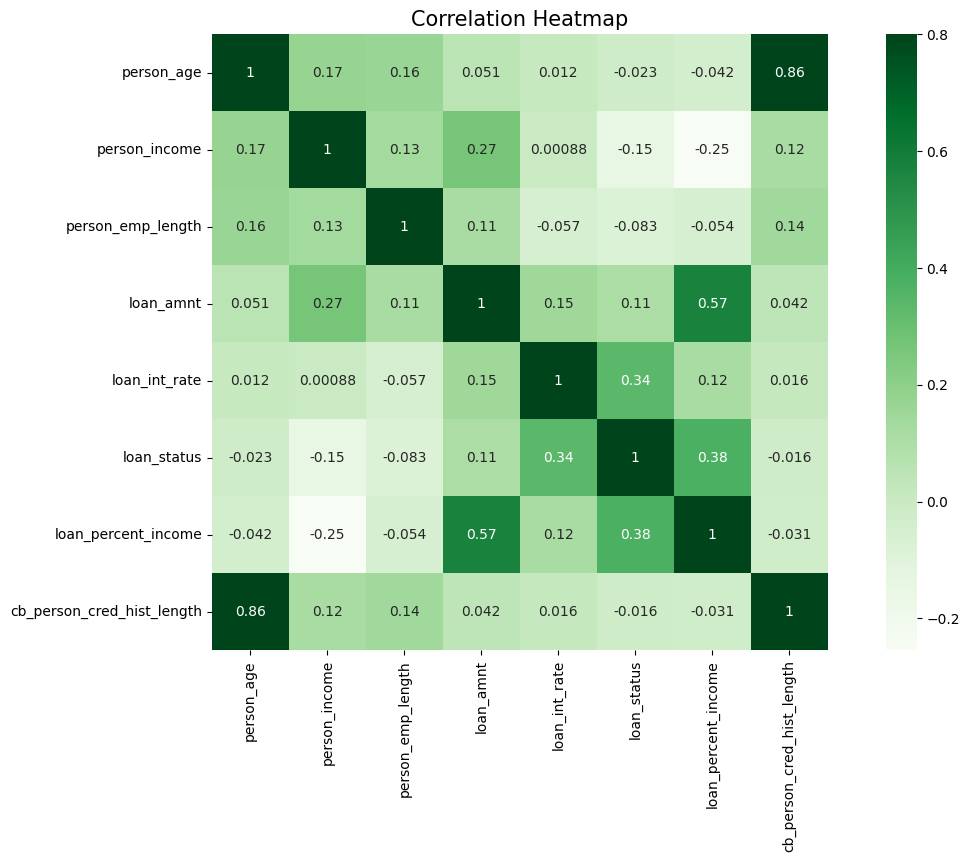

In [12]:
fig, ax = plt.subplots()
fig.set_size_inches(15,8)
sns.heatmap(df.corr(numeric_only=True), vmax =.8, square = True, annot = True,cmap='Greens' )
plt.title('Correlation Heatmap',fontsize=15);

### **2. Handling Missing Values**


In [13]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,887
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3095
loan_status,0
loan_percent_income,0


In [14]:
Nan_per = df.isnull().sum()/df.shape[0]*100
Nan_per.round(2)

,0
person_age,0.00
person_income,0.00
person_home_ownership,0.00
person_emp_length,2.74
loan_intent,0.00
loan_grade,0.00
loan_amnt,0.00
loan_int_rate,9.55
loan_status,0.00
loan_percent_income,0.00


* person_emp_length contains 2.74% missing values
* loan_int_rate contains 9.55% missing values

Total missing values = 12.29% of the dataset, which can't be dropped.

In [15]:
df["person_emp_length"] = df["person_emp_length"].fillna(df["person_emp_length"].median())
df["loan_int_rate"] = df["loan_int_rate"].fillna(df["loan_int_rate"].median())

df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,0
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,0
loan_status,0
loan_percent_income,0


### **3. Visualize Data Relationships**

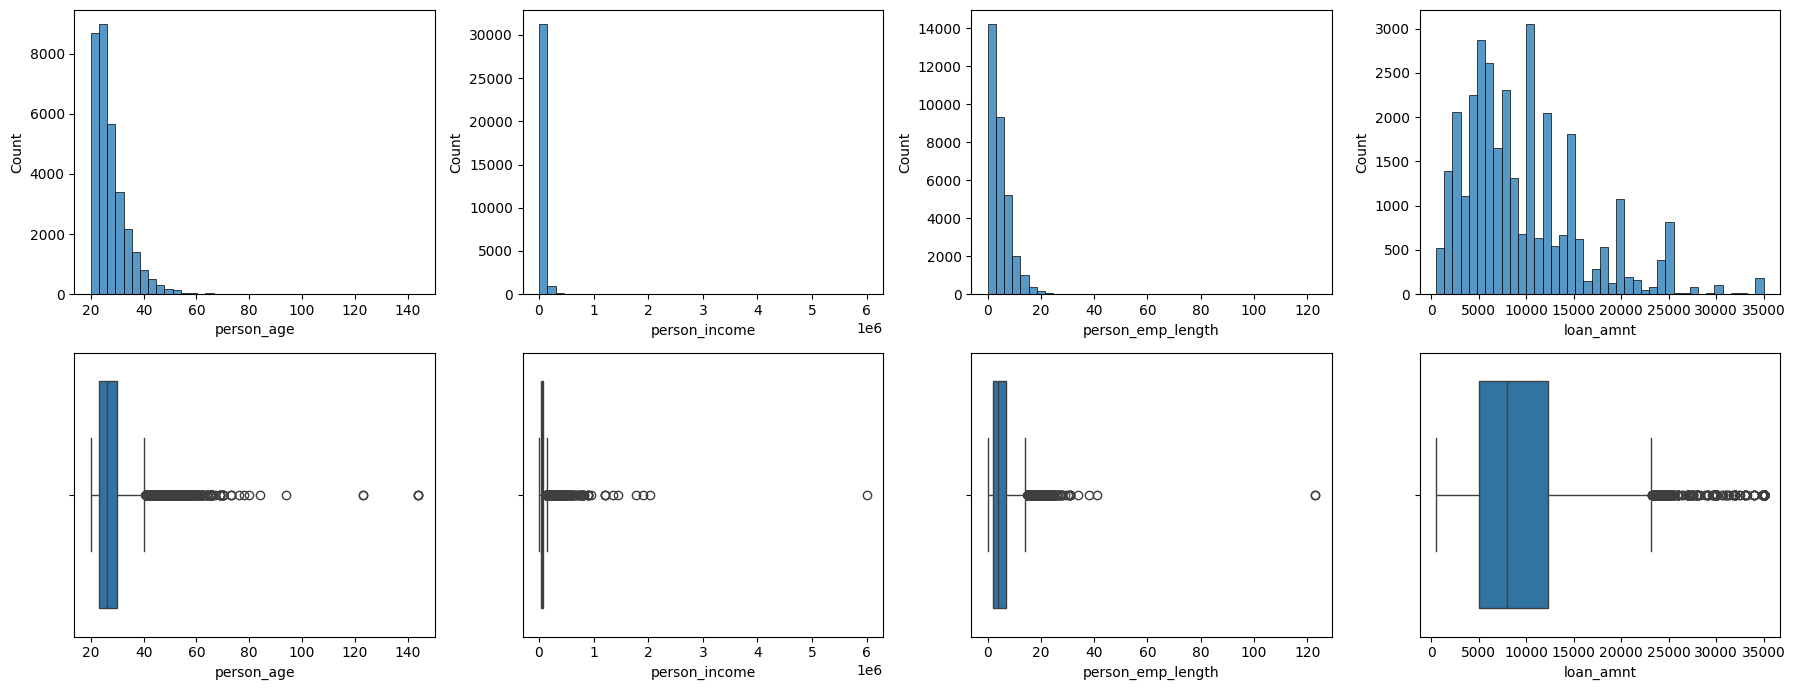

In [16]:
num_cols = ["person_age", "person_income", "person_emp_length", "loan_amnt"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, c in enumerate(num_cols):
    sns.histplot(df[c], ax=axes[0, i], bins=40)
    sns.boxplot(x=df[c], ax=axes[1, i])
plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Loan status (0 = repaid, 1 = default)')

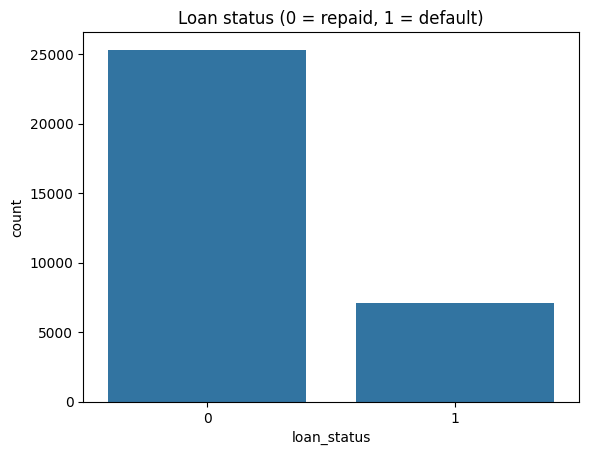

In [17]:
sns.countplot(x="loan_status", data=df)
plt.title("Loan status (0 = repaid, 1 = default)")

* Most of the loan_status is 0 which causes 1 (default) to be minority so the data is imbalanced

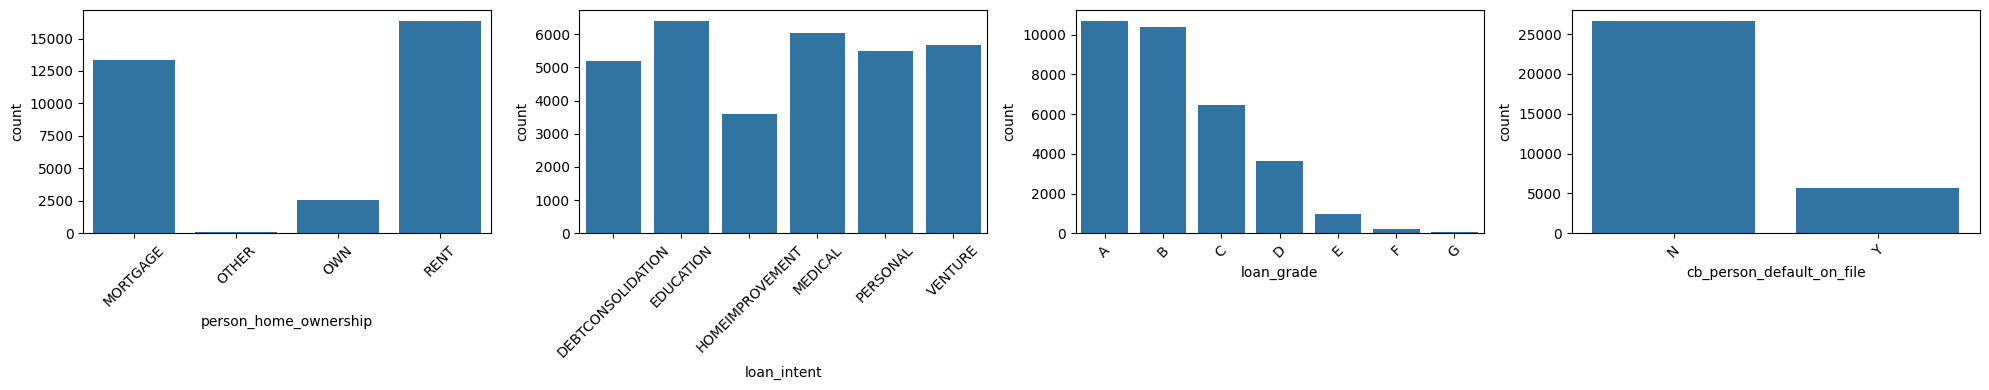

In [18]:
cat_cols = ["person_home_ownership", "loan_intent", "loan_grade", "cb_person_default_on_file"]
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, c in zip(axes, cat_cols):
    sns.countplot(x=c, data=df, ax=ax, order=sorted(df[c].dropna().unique()))
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()

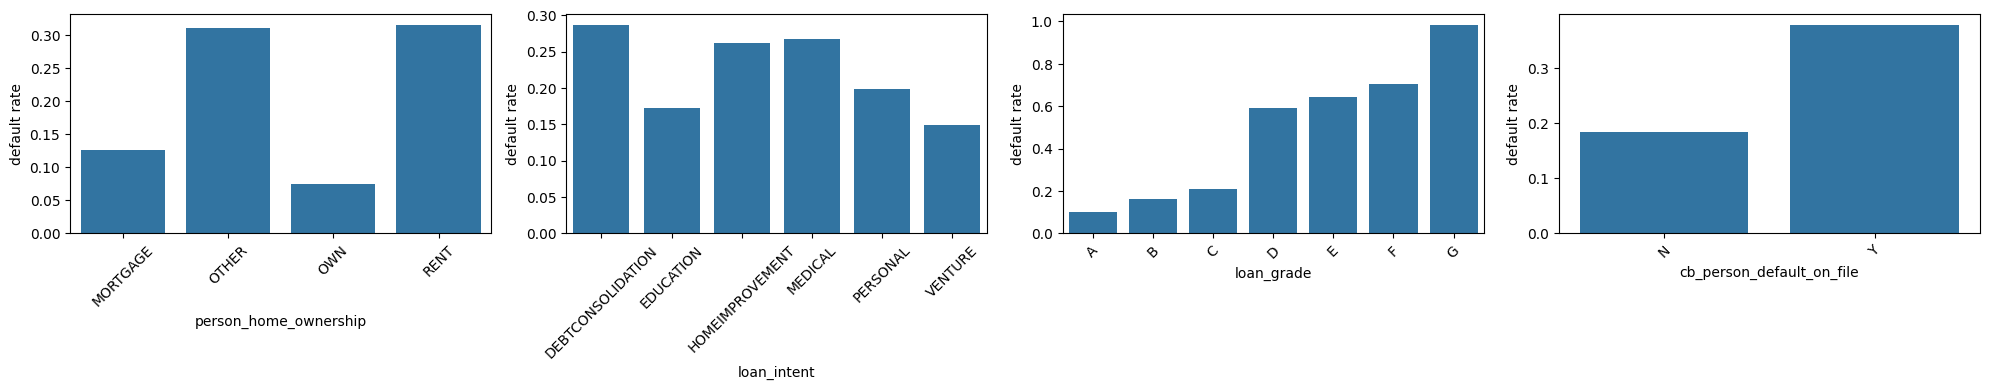

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, c in zip(axes, cat_cols):
    rate = df.groupby(c)["loan_status"].mean().sort_index()
    sns.barplot(x=rate.index, y=rate.values, ax=ax)
    ax.set_ylabel("default rate")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()

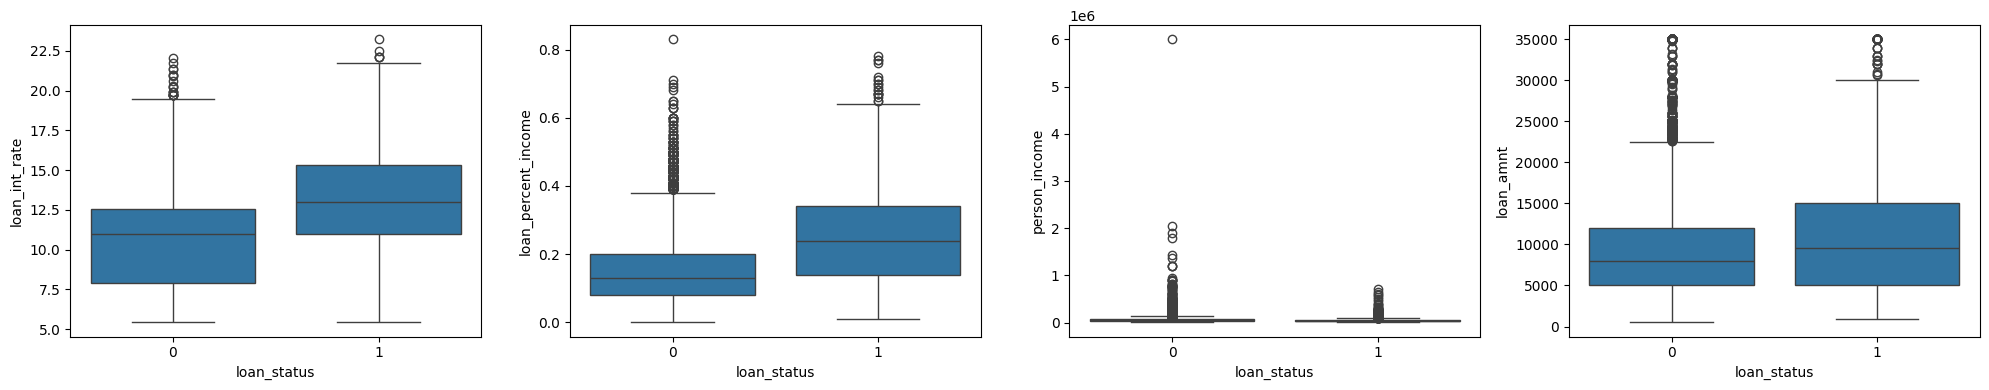

In [20]:
cols = ["loan_int_rate", "loan_percent_income", "person_income", "loan_amnt"]
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, c in zip(axes, cols):
    sns.boxplot(x="loan_status", y=c, data=df, ax=ax)
plt.tight_layout()

<Axes: xlabel='person_income', ylabel='loan_amnt'>

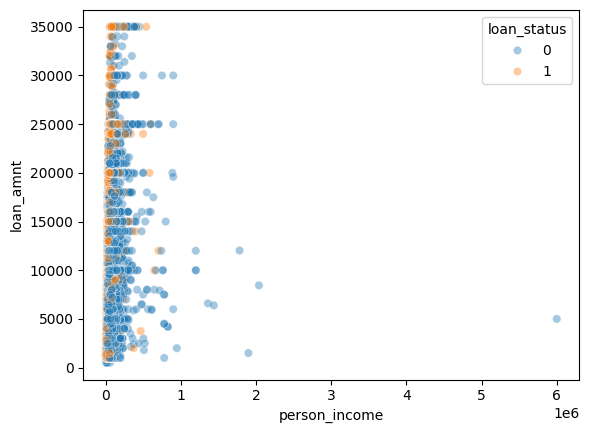

In [21]:
sns.scatterplot(x="person_income", y="loan_amnt", hue="loan_status", data=df, alpha=0.4)

<Axes: xlabel='person_age', ylabel='cb_person_cred_hist_length'>

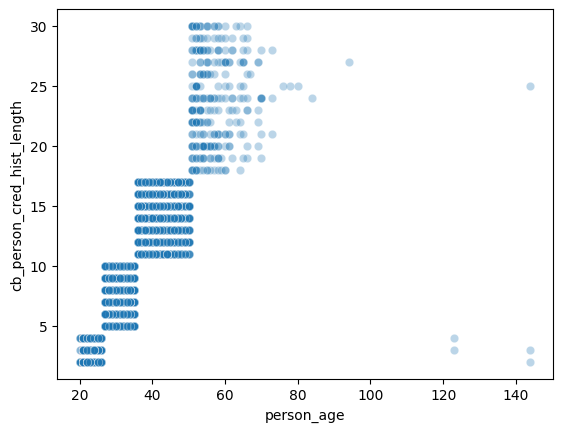

In [22]:
sns.scatterplot(x="person_age", y="cb_person_cred_hist_length", data=df, alpha=0.3)

### **4. Handling Outliers**

In [23]:
df[["person_age", "person_income", "person_emp_length", "loan_amnt",
        "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length"]].describe().T

,count,mean,std,min,25%,50%,75%,max
person_age,32416.0,27.747008,6.354100,20.00,23.00,26.00,30.00,144.00
person_income,32416.0,66091.640826,62015.580269,4000.00,38542.00,55000.00,79218.00,6000000.00
person_emp_length,32416.0,4.768880,4.090411,0.00,2.00,4.00,7.00,123.00
loan_amnt,32416.0,9593.845632,6322.730241,500.00,5000.00,8000.00,12250.00,35000.00
loan_int_rate,32416.0,11.014662,3.083050,5.42,8.49,10.99,13.11,23.22
loan_percent_income,32416.0,0.170250,0.106812,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32416.0,5.811297,4.059030,2.00,3.00,4.00,8.00,30.00


In [24]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((s < low) | (s > high)).sum(), low, high

for c in ["person_age", "person_income", "person_emp_length", "loan_amnt"]:
    n, low, high = iqr_outliers(df[c].dropna())
    print(f"{c}: {n} outliers (outside {low:.1f} to {high:.1f})")

person_age: 1491 outliers (outside 12.5 to 40.5)
person_income: 1478 outliers (outside -22472.0 to 140232.0)
person_emp_length: 852 outliers (outside -5.5 to 14.5)
loan_amnt: 1679 outliers (outside -5875.0 to 23125.0)


99th percentile: 225000.0
rows above cap: 322


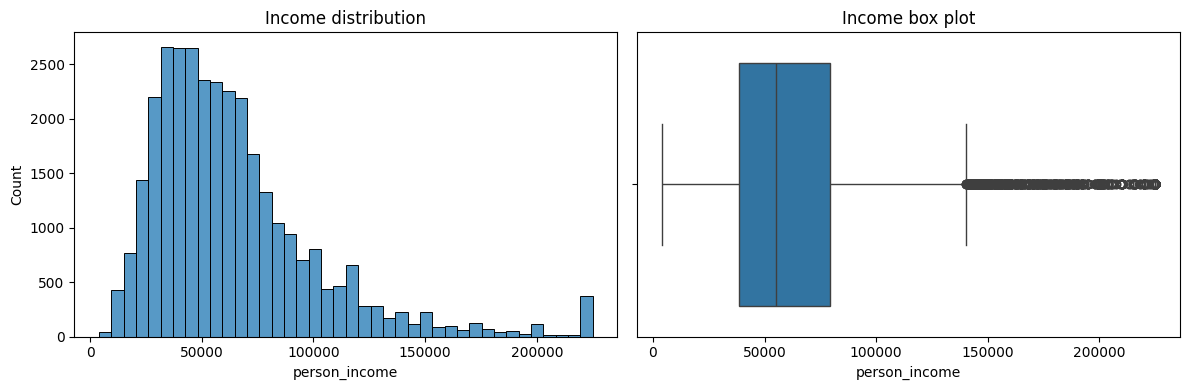

In [25]:
bad_age = df["person_age"] > 100
df = df[~bad_age].copy()
df.loc[df["person_emp_length"] > 60, "person_emp_length"] = np.nan

cap = df["person_income"].quantile(0.99)
print("99th percentile:", cap)
print("rows above cap:", (df["person_income"] > cap).sum())

df["person_income"] = df["person_income"].clip(upper=cap)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['person_income'], bins=40, ax=axes[0])
sns.boxplot(x=df['person_income'], ax=axes[1])
axes[0].set_title("Income distribution")
axes[1].set_title("Income box plot")
plt.tight_layout()
plt.show()

* Ages above 100 and employment above 60 years were treated as errors and filled with median

### **Pipelines**

In [26]:
target_col = "loan_status"
X = df.drop(columns=[target_col])
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=29, stratify=y
)

num_cols = ["person_age", "person_income", "person_emp_length", "loan_amnt",
            "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length"]
nominal_cols = ["person_home_ownership", "loan_intent"]
grade_col = ["loan_grade"]
binary_col = ["cb_person_default_on_file"]

numerical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipe, num_cols),
    ("nom", OneHotEncoder(handle_unknown="ignore"), nominal_cols),
    ("grade", OrdinalEncoder(categories=[list("ABCDEFG")]), grade_col),
    ("bin", OrdinalEncoder(categories=[["N", "Y"]]), binary_col),
])

# **Models**

---



,accuracy,precision,recall,f1,roc_auc
Model,,,,,
Logistic Regression,0.787 ± 0.008,0.509 ± 0.012,0.779 ± 0.007,0.615 ± 0.010,0.863 ± 0.006
Naive Bayes,0.816 ± 0.004,0.566 ± 0.008,0.673 ± 0.013,0.615 ± 0.010,0.838 ± 0.005
Random Forest,0.933 ± 0.002,0.978 ± 0.005,0.710 ± 0.008,0.823 ± 0.007,0.933 ± 0.003
Gradient Boosting,0.934 ± 0.002,0.967 ± 0.009,0.722 ± 0.011,0.827 ± 0.007,0.937 ± 0.003
SVM,0.881 ± 0.005,0.710 ± 0.014,0.771 ± 0.015,0.739 ± 0.010,0.909 ± 0.006


/tmp/ipykernel_2999/2007556059.py:47: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([cv_results[n]["test_roc_auc"] for n in pipelines],


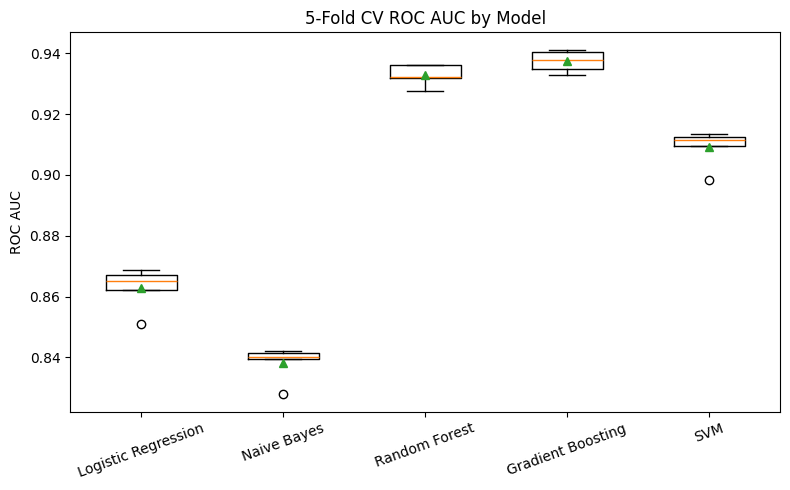

In [27]:
def to_dense(X):
    return X.toarray() if hasattr(X, "toarray") else X

pipelines = {
    "Logistic Regression": Pipeline([
        ("prep", preprocessor),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
    ]),
    "Naive Bayes": Pipeline([
        ("prep", preprocessor),
        ("dense", FunctionTransformer(to_dense)),
        ("clf", GaussianNB()),
    ]),
    "Random Forest": Pipeline([
        ("prep", preprocessor),
        ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                       random_state=42, n_jobs=-1)),
    ]),
    "Gradient Boosting": Pipeline([
        ("prep", preprocessor),
        ("clf", GradientBoostingClassifier(n_estimators=200, learning_rate=0.1,
                                           max_depth=3, random_state=42)),
    ]),
    "SVM": Pipeline([
        ("prep", preprocessor),
        ("clf", SVC(kernel="rbf", C=1.0, gamma="scale",
                    class_weight="balanced", random_state=42)),
    ]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

cv_results, rows = {}, []
for name, pipe in pipelines.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)  # training data only
    cv_results[name] = scores
    row = {"Model": name}
    for m in scoring:
        vals = scores[f"test_{m}"]
        row[m] = f"{vals.mean():.3f} ± {vals.std():.3f}"
    rows.append(row)

display(pd.DataFrame(rows).set_index("Model"))

plt.figure(figsize=(8, 5))
plt.boxplot([cv_results[n]["test_roc_auc"] for n in pipelines],
            labels=list(pipelines), showmeans=True)
plt.ylabel("ROC AUC")
plt.title("5-Fold CV ROC AUC by Model")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Accuracy: 0.80
Confusion matrix:
 [[4045 1020]
 [ 304 1114]]
Precision: 0.52
Recall: 0.79
F1 score: 0.63


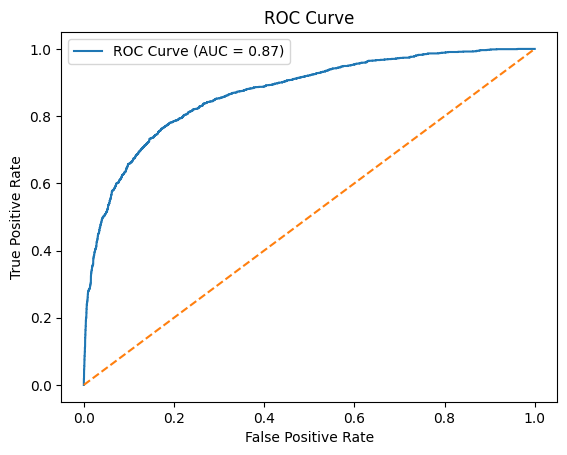

In [28]:
# Logistic Regression
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, precision_score, recall_score,
    f1_score, roc_curve, roc_auc_score
)
import matplotlib.pyplot as plt

model = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")

cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix:\n", cm)

precision = precision_score(y_test, y_pred)
print(f"Precision: {precision:.2f}")

recall = recall_score(y_test, y_pred)
print(f"Recall: {recall:.2f}")

f1 = f1_score(y_test, y_pred)
print(f"F1 score: {f1:.2f}")

# ROC curve (reuses y_prob computed above)
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)

plt.figure()
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

Accuracy: 0.82
Confusion matrix:
 [[4353  712]
 [ 449  969]]
Precision: 0.58
Recall: 0.68
F1 score: 0.63


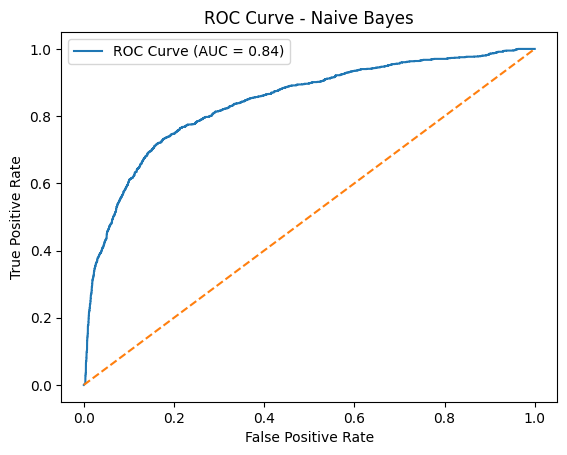

In [29]:
#Naive Bayes
def to_dense(X):
    return X.toarray() if hasattr(X, "toarray") else X

nb_model = Pipeline([
    ("prep", preprocessor),
    ("dense", FunctionTransformer(to_dense)),
    ("clf", GaussianNB()),
])

nb_model.fit(X_train, y_train)
y_pred_nb = nb_model.predict(X_test)
y_prob_nb = nb_model.predict_proba(X_test)[:, 1]

print(f"Accuracy: {accuracy_score(y_test, y_pred_nb):.2f}")
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred_nb))
print(f"Precision: {precision_score(y_test, y_pred_nb):.2f}")
print(f"Recall: {recall_score(y_test, y_pred_nb):.2f}")
print(f"F1 score: {f1_score(y_test, y_pred_nb):.2f}")

# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_prob_nb)
roc_auc = roc_auc_score(y_test, y_prob_nb)

plt.figure()
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Naive Bayes")
plt.legend()
plt.show()

Accuracy: 0.93
Confusion matrix:
 [[5044   21]
 [ 409 1009]]
Precision: 0.98
Recall: 0.71
F1 score: 0.82


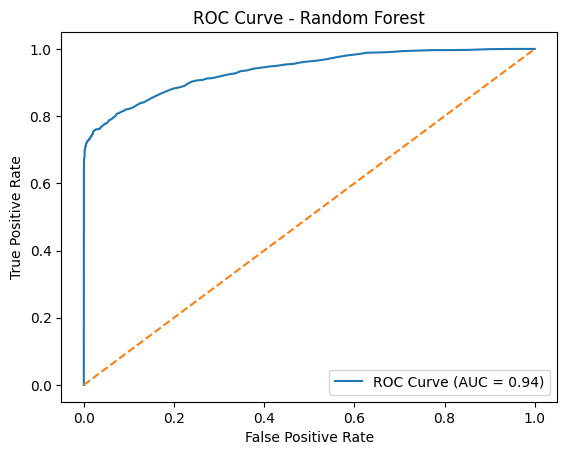

In [30]:
#Random Forest
rf_model = Pipeline([
    ("prep", preprocessor),
    ("clf", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    )),
])

rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.2f}")
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred_rf))
print(f"Precision: {precision_score(y_test, y_pred_rf):.2f}")
print(f"Recall: {recall_score(y_test, y_pred_rf):.2f}")
print(f"F1 score: {f1_score(y_test, y_pred_rf):.2f}")

# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_prob_rf)
roc_auc = roc_auc_score(y_test, y_prob_rf)

plt.figure()
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend()
plt.show()

Accuracy: 0.90
Confusion matrix:
 [[4691  374]
 [ 271 1147]]
Precision: 0.75
Recall: 0.81
F1 score: 0.78


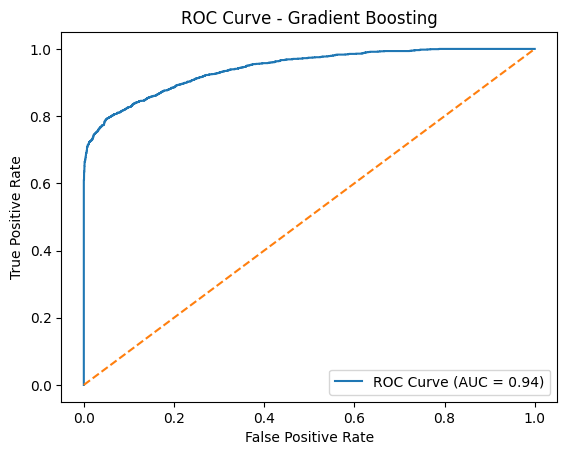

In [31]:
#Gradient Boosting
gb_model = Pipeline([
    ("prep", preprocessor),
    ("clf", GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=3,
        random_state=42,
    )),
])

# GradientBoostingClassifier has no class_weight, so balance via sample weights
weights = compute_sample_weight("balanced", y_train)
gb_model.fit(X_train, y_train, clf__sample_weight=weights)

y_pred_gb = gb_model.predict(X_test)
y_prob_gb = gb_model.predict_proba(X_test)[:, 1]

print(f"Accuracy: {accuracy_score(y_test, y_pred_gb):.2f}")
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred_gb))
print(f"Precision: {precision_score(y_test, y_pred_gb):.2f}")
print(f"Recall: {recall_score(y_test, y_pred_gb):.2f}")
print(f"F1 score: {f1_score(y_test, y_pred_gb):.2f}")

# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_prob_gb)
roc_auc = roc_auc_score(y_test, y_prob_gb)

plt.figure()
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Gradient Boosting")
plt.legend()
plt.show()

Accuracy: 0.88
Confusion matrix:
 [[4637  428]
 [ 330 1088]]
Precision: 0.72
Recall: 0.77
F1 score: 0.74


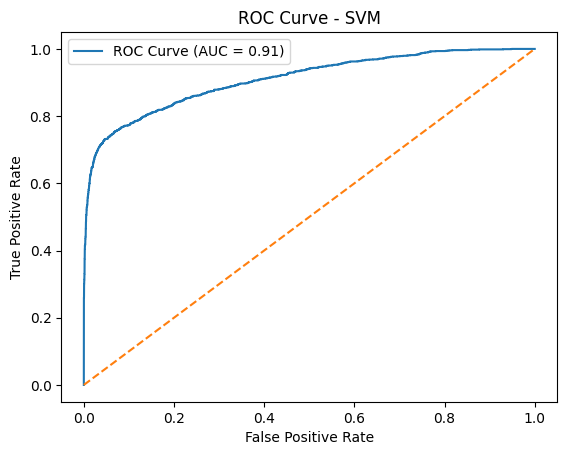

In [32]:
#Support Vector Machines (SVM)
svm_model = Pipeline([
    ("prep", preprocessor),
    ("clf", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced",
        probability=True,
        random_state=42,
    )),
])

svm_model.fit(X_train, y_train)
y_pred_svm = svm_model.predict(X_test)
y_prob_svm = svm_model.predict_proba(X_test)[:, 1]

print(f"Accuracy: {accuracy_score(y_test, y_pred_svm):.2f}")
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred_svm))
print(f"Precision: {precision_score(y_test, y_pred_svm):.2f}")
print(f"Recall: {recall_score(y_test, y_pred_svm):.2f}")
print(f"F1 score: {f1_score(y_test, y_pred_svm):.2f}")

# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_prob_svm)
roc_auc = roc_auc_score(y_test, y_prob_svm)

plt.figure()
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - SVM")
plt.legend()
plt.show()

,Accuracy,Precision,Recall,F1,ROC AUC
Model,,,,,
Gradient Boosting,0.901,0.754,0.809,0.781,0.942
Random Forest,0.934,0.980,0.712,0.824,0.937
SVM,0.883,0.718,0.767,0.742,0.909
Logistic Regression,0.796,0.522,0.786,0.627,0.869
Naive Bayes,0.821,0.576,0.683,0.625,0.841


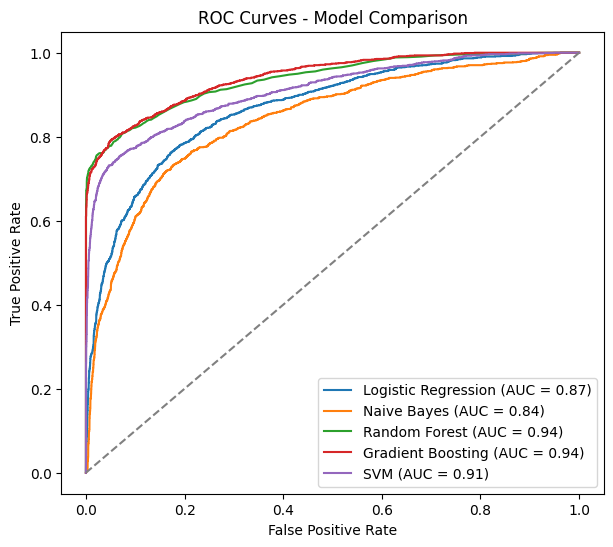

In [33]:
models = {
    "Logistic Regression": (y_pred,     y_prob),
    "Naive Bayes":         (y_pred_nb,  y_prob_nb),
    "Random Forest":       (y_pred_rf,  y_prob_rf),
    "Gradient Boosting":   (y_pred_gb,  y_prob_gb),
    "SVM":                 (y_pred_svm, y_prob_svm),
}

# Metrics table
rows = []
for name, (pred, prob) in models.items():
    rows.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall":    recall_score(y_test, pred),
        "F1":        f1_score(y_test, pred),
        "ROC AUC":   roc_auc_score(y_test, prob),
    })

results = (
    pd.DataFrame(rows)
    .set_index("Model")
    .sort_values("ROC AUC", ascending=False)
    .round(3)
)
display(results)

plt.figure(figsize=(7, 6))
for name, (pred, prob) in models.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, prob):.2f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Model Comparison")
plt.legend(loc="lower right")
plt.show()